# Phase 4 — Customer-Level RFM Feature Engineering

**Project:** AI-Based Customer Segmentation and Purchasing Behaviour Analysis Using Machine Learning

## Objective
Convert cleaned purchase-line data into one row per customer with RFM features:
- **Recency:** days since the customer's latest purchase.
- **Frequency:** number of distinct valid invoices/orders.
- **Monetary:** sum of positive purchase line values (`Quantity × UnitPrice`) in the dataset's currency (GBP).

Additional profiling fields are included for interpretation, but the three RFM fields are the core clustering features.

## Data policy
This notebook starts from `Online_Retail_Cleaned_Purchase_Lines.csv`, produced in Phase 3. That preprocessing retained identified customers and positive purchase lines, removed exact duplicate rows, and excluded cancellation invoices beginning with `C`. Consequently, Monetary represents retained positive purchases, not net spend after refunds/returns.

The reference date is the calendar day after the latest invoice date in the cleaned data. This avoids calculating zero recency for the last purchase date and makes the policy reproducible.

In [1]:
import os
from pathlib import Path
# Work inside data/processed (found from the notebook folder upwards); paths below are relative to it.
for _d in [Path.cwd(), *Path.cwd().parents]:
    if (_d / "data" / "processed").is_dir():
        os.chdir(_d / "data" / "processed")
        break
print("Data folder:", Path.cwd().name)
import pandas as pd
import numpy as np
from pathlib import Path

INPUT_FILE = Path("Online_Retail_Cleaned_Purchase_Lines.csv")
OUTPUT_FILE = Path("Phase4_Customer_RFM.csv")

# Read identifiers as text so codes such as "85123A" and "71053" are handled consistently.
df = pd.read_csv(INPUT_FILE, parse_dates=["InvoiceDate"], dtype={"InvoiceNo": str, "StockCode": str})
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()

print("Input shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Data folder: processed


Input shape: (392692, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'LineValue']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [2]:
# Validate assumptions before aggregating
required = ["CustomerID", "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "LineValue", "StockCode", "Country"]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

checks = {
    "Missing CustomerID": int(df["CustomerID"].isna().sum()),
    "Non-positive Quantity rows": int((df["Quantity"] <= 0).sum()),
    "Non-positive UnitPrice rows": int((df["UnitPrice"] <= 0).sum()),
    "Cancellation-prefix invoices": int(df["InvoiceNo"].str.upper().str.startswith("C").sum()),
    "Duplicate full rows": int(df.duplicated().sum()),
    "LineValue != Quantity x UnitPrice": int((~np.isclose(df["LineValue"], df["Quantity"] * df["UnitPrice"])).sum()),
}
for name, value in checks.items():
    print(f"{name}: {value}")
assert all(v == 0 for v in checks.values()), "Input violates the Phase 3 positive-purchase policy"

Missing CustomerID: 0
Non-positive Quantity rows: 0
Non-positive UnitPrice rows: 0
Cancellation-prefix invoices: 0
Duplicate full rows: 0
LineValue != Quantity x UnitPrice: 0


In [3]:
# Reference date: next calendar day after latest transaction timestamp
latest_date = df["InvoiceDate"].max()
snapshot_date = latest_date.normalize() + pd.Timedelta(days=1)

# Customer-level aggregation. Frequency counts distinct invoice numbers, not line items.
rfm = (
    df.dropna(subset=["CustomerID"])
      .groupby("CustomerID")
      .agg(
          LastPurchaseDate=("InvoiceDate", "max"),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("LineValue", "sum"),
          TotalItems=("Quantity", "sum"),
          DistinctProducts=("StockCode", "nunique"),
          Country=("Country", lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
      )
      .reset_index()
)

rfm["Recency"] = (snapshot_date - rfm["LastPurchaseDate"].dt.normalize()).dt.days
rfm = rfm[[
    "CustomerID", "Recency", "Frequency", "Monetary",
    "TotalItems", "DistinctProducts", "Country", "LastPurchaseDate"
]]
rfm["Monetary"] = rfm["Monetary"].round(2)

print("Latest transaction:", latest_date)
print("Reference date:", snapshot_date.date())
print("RFM shape:", rfm.shape)
display(rfm.head())


Latest transaction: 2011-12-09 12:50:00
Reference date: 2011-12-10
RFM shape: (4338, 8)


,CustomerID,Recency,Frequency,Monetary,TotalItems,DistinctProducts,Country,LastPurchaseDate
0,12346,326,1,77183.60,74215,1,United Kingdom,2011-01-18 10:01:00
1,12347,3,7,4310.00,2458,103,Iceland,2011-12-07 15:52:00
2,12348,76,4,1797.24,2341,22,Finland,2011-09-25 13:13:00
3,12349,19,1,1757.55,631,73,Italy,2011-11-21 09:51:00
4,12350,311,1,334.40,197,17,Norway,2011-02-02 16:01:00


In [4]:
# Quality checks
assert rfm["CustomerID"].is_unique, "Expected one row per customer."
assert rfm[["Recency", "Frequency", "Monetary"]].isna().sum().sum() == 0
assert (rfm["Recency"] >= 1).all()          # reference date is the day after the latest invoice
assert (rfm["Frequency"] >= 1).all()
assert (rfm["Monetary"] > 0).all()
assert len(rfm) == df["CustomerID"].nunique()
assert rfm["Frequency"].sum() == df["InvoiceNo"].nunique()   # each invoice belongs to exactly one customer
assert (rfm["Frequency"] <= df.groupby("CustomerID").size().values).all()
assert abs(rfm["Monetary"].sum() - df["LineValue"].sum()) < 0.01 * len(rfm)  # equal up to per-customer rounding

print("Unique customers:", rfm["CustomerID"].nunique())
print("Duplicate customer IDs:", int(rfm["CustomerID"].duplicated().sum()))
print("Missing core RFM values:", int(rfm[["Recency", "Frequency", "Monetary"]].isna().sum().sum()))
print("Distinct invoices:", df["InvoiceNo"].nunique(), "| Sum of Frequency:", int(rfm["Frequency"].sum()))
print("Customers whose records span >1 country (Country = most frequent; ties -> alphabetical first):",
      int((df.groupby("CustomerID")["Country"].nunique() > 1).sum()))

Unique customers: 4338
Duplicate customer IDs: 0
Missing core RFM values: 0
Distinct invoices: 18532 | Sum of Frequency: 18532
Customers whose records span >1 country (Country = most frequent; ties -> alphabetical first): 8


In [5]:
# Descriptive statistics and distribution checks
core = ["Recency", "Frequency", "Monetary"]
rfm_stats = rfm[core + ["TotalItems", "DistinctProducts"]].agg(["count", "mean", "median", "var", "std", "min", "max"]).T
rfm_stats["range"] = rfm_stats["max"] - rfm_stats["min"]
rfm_stats["skewness"] = rfm[core + ["TotalItems", "DistinctProducts"]].skew()
display(rfm_stats)

# Relationships between the RFM features: covariance (raw), Pearson (log1p F and M) and Spearman (rank-based)
display(rfm[core].cov().rename_axis("Covariance"))
log_view = rfm[core].assign(Frequency=np.log1p(rfm["Frequency"]), Monetary=np.log1p(rfm["Monetary"]))
display(log_view.corr(method="pearson").rename_axis("Pearson (log1p F, M)"))
spearman = rfm[core].corr(method="spearman")
display(spearman.rename_axis("Spearman"))

# Monetary should be described as positive-purchase spend under the Phase 3 filtering policy.
print("Total retained positive-purchase value:", round(rfm["Monetary"].sum(), 2))

,count,mean,median,var,std,min,max,range,skewness
Recency,4338.0,93.059474,51.00,1.000245e+04,100.012264,1.00,374.00,373.00,1.245826
Frequency,4338.0,4.272015,2.00,5.925917e+01,7.697998,1.00,209.00,208.00,12.067031
Monetary,4338.0,2048.688080,668.57,8.073436e+07,8985.230220,3.75,280206.02,280202.27,19.339368
TotalItems,4338.0,1187.644537,378.00,2.543810e+07,5043.619654,1.00,196915.00,196914.00,20.383991
DistinctProducts,4338.0,61.501153,35.00,7.287485e+03,85.366768,1.00,1787.00,1786.00,6.919445


,Recency,Frequency,Monetary
Covariance,,,
Recency,10002.452999,-200.775462,-1.096104e+05
Frequency,-200.775462,59.259171,3.823482e+04
Monetary,-109610.371779,38234.824982,8.073436e+07


,Recency,Frequency,Monetary
"Pearson (log1p F, M)",,,
Recency,1.000000,-0.472983,-0.434474
Frequency,-0.472983,1.000000,0.808119
Monetary,-0.434474,0.808119,1.000000


,Recency,Frequency,Monetary
Spearman,,,
Recency,1.000000,-0.563001,-0.481544
Frequency,-0.563001,1.000000,0.807185
Monetary,-0.481544,0.807185,1.000000


Total retained positive-purchase value: 8887208.89


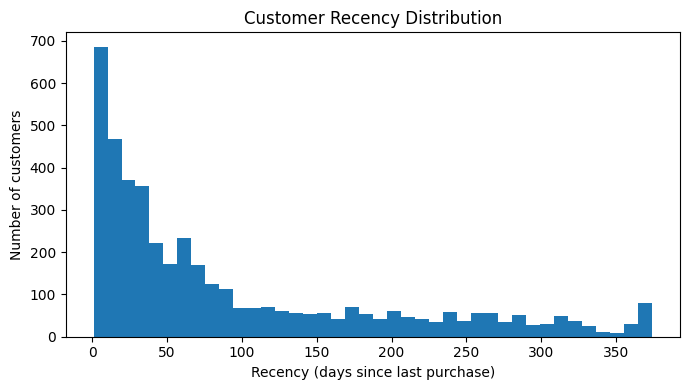

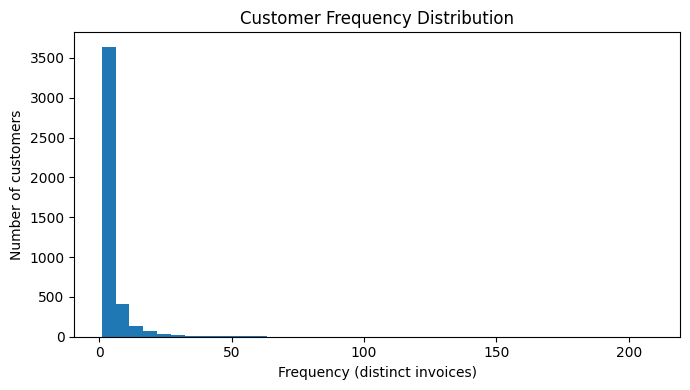

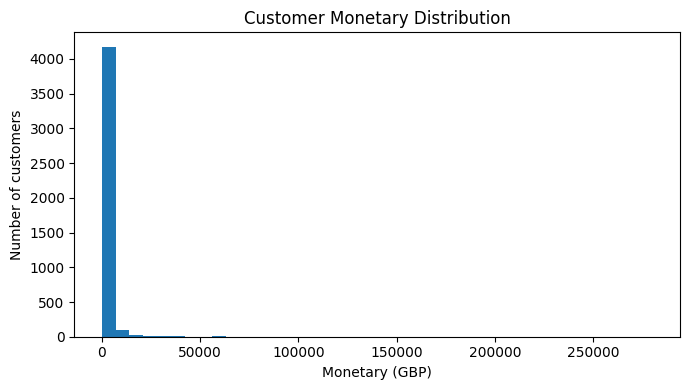

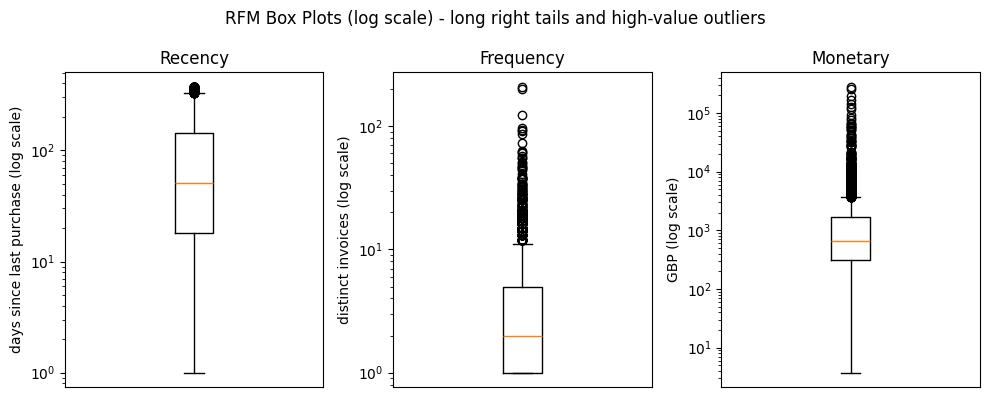

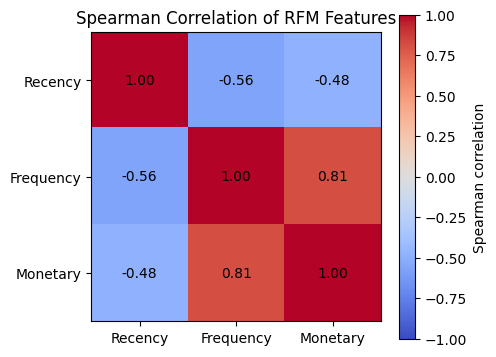

In [6]:
# Visualize the core RFM distributions (raw scales) and their relationships
import matplotlib.pyplot as plt
FIG_DIR = Path("../../artifacts/phase_outputs/phase4_outputs")
FIG_DIR.mkdir(exist_ok=True)
units = {"Recency": "days since last purchase", "Frequency": "distinct invoices", "Monetary": "GBP"}

for col in ["Recency", "Frequency", "Monetary"]:
    plt.figure(figsize=(7, 4))
    plt.hist(rfm[col], bins=40)
    plt.title(f"Customer {col} Distribution")
    plt.xlabel(f"{col} ({units[col]})")
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{col.lower()}_histogram.png", dpi=150)
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.boxplot(rfm[col])
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_ylabel(f"{units[col]} (log scale)")
    ax.set_xticks([])
fig.suptitle("RFM Box Plots (log scale) - long right tails and high-value outliers")
fig.tight_layout()
plt.savefig(FIG_DIR / "rfm_boxplots_log.png", dpi=150)
plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(spearman, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Spearman correlation")
plt.xticks(range(3), spearman.columns)
plt.yticks(range(3), spearman.index)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{spearman.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Spearman Correlation of RFM Features")
plt.tight_layout()
plt.savefig(FIG_DIR / "rfm_spearman_heatmap.png", dpi=150)
plt.show()

In [7]:
# Save the customer-level feature table
rfm.to_csv(OUTPUT_FILE, index=False, lineterminator="\n")
print(f"Saved: {OUTPUT_FILE}")


Saved: Phase4_Customer_RFM.csv


## Interpretation and next phase
- Lower Recency means a more recent customer purchase.
- Higher Frequency means more distinct purchase invoices.
- Higher Monetary means more retained positive-purchase value.
- RFM distributions are typically right-skewed, especially Frequency and Monetary. In Phase 5, inspect skew and compare a `log1p` transformation with scaling before K-Means.
- Do not include `CustomerID`, `Country`, or `LastPurchaseDate` directly as numeric clustering features. They are identifiers/context fields, not RFM measurements.
- This phase does not train or evaluate a clustering model; that belongs in Phase 5/6.

**Important limitation:** cancelled invoices and non-positive purchase lines were excluded in Phase 3, so this feature table does not measure net spending after refunds. Document this in the final report.